# pure-evo-regime (#1 / #2) *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — approval-gated (see `Research/README.md`).

## Question

**What metaparameter regime maximizes open-ended activity under *joint* (LUT+egene) vs
*LUT-only* evolution?** And which excess metric actually tracks it?

## Method

Two mirrored pure-evolution scans, corrected excess metrics, N=256, 8000 ticks:

- **#1 `pure_evo_joint`** — LUT and egene both evolve (300 configs).
- **#2 `pure_evo_lut_only`** — egene frozen (`mu_egene = mu_egenome = tax_per_egene = 0`), 180
  configs, 0 extinct.

**Model.** The scans first ran under the legacy uncapped mouthful (`food_cap=0`), which is not part of the model. This digest reads the 2026-10-23 standard-model rescans (`food_cap=1`; same configs and protocol, today's code; the rule can bind in 237 of 300 and 151 of 180 rows with `m_scale > 1`).

Axes: `mu_lut`, `m_scale`, `food_inc`. Metrics: whole-genome `excess_pc`, fixed-space
`dyn_excess_pc`, `eg_excess_pc`.

## Headline result (standard model, 2026-10-23)

- **Whole-genome `excess_pc` ≈ 0 everywhere**: it does not discriminate regimes (a direct
  consequence of the scope bug documented in `neutral-model-methodology`). Unchanged.
- **`dyn` / `eg` excess is strongly positive** and *does* discriminate. Unchanged.
- **The composite optimum is low `mu_lut` + high `m_scale`**: cfg 41 (`mu_lut` 0.01, `m_scale` 2.5)
  ranks first under both rules (contradicting the 2026-04-27 optimum of `mu_lut = 0.06`, which
  under today's model no longer wins even its own scan). It is carried by the `eg` channel: the
  `dyn` channel is lowest at `m_scale` 2.5 and peaks at `m_scale` 1.2-2.0 with `mu_lut` 0.03-0.06.
- **The `mu_lut` optimum is conditional on egene only in the composite's top ranks**: the joint
  top-5 sit at `mu_lut` 0.01-0.06, the LUT-only top-5 at 0.06-0.15. **"Egene-freeze reduces
  `dyn`-excess" does not hold in the marginal means** (rescan or recorded): averaged over all rows,
  joint and LUT-only `dyn` excess are about equal (25.4 vs 26.0), and LUT-only is higher at
  `mu_lut` 0.01. #2 also zeroes `tax_per_egene`, so #1 vs #2 confounds egene mutation with egene cost.

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_food-cap-standard


In [2]:
S = ROOT / "Research/Activity-metrics/Scans"
joint = pd.read_csv(S / "2026-10-23_pure_evo_joint_standard/results.csv")      # standard-model rescans
lut   = pd.read_csv(S / "2026-10-23_pure_evo_lut_only_standard/results.csv")
for name, d in [("#1 joint", joint), ("#2 lut_only", lut)]:
    print(f"{name}: {len(d)} rows, extinct={int(d.extinct.sum())}")
print()
print("whole-genome excess_pc_final  (joint): mean=%.3f  |max|=%.3f  <-- ~0, non-discriminating"
      % (joint.excess_pc_final.mean(), joint.excess_pc_final.abs().max()))
print("dyn_excess_pc_slope (joint): mean=%.2f   eg_excess_pc_slope: mean=%.2f"
      % (joint.dyn_excess_pc_slope.mean(), joint.eg_excess_pc_slope.mean()))

#1 joint: 300 rows, extinct=9
#2 lut_only: 180 rows, extinct=0

whole-genome excess_pc_final  (joint): mean=0.779  |max|=5.245  <-- ~0, non-discriminating
dyn_excess_pc_slope (joint): mean=25.42   eg_excess_pc_slope: mean=26.29


### Whole-genome excess is flat; fixed-space excess is alive

The whole-genome `excess_pc` distribution sits at ~0 across all 300 joint configs, while the
`dyn`/`eg` excess spreads widely — the fixed-space metrics carry the signal.

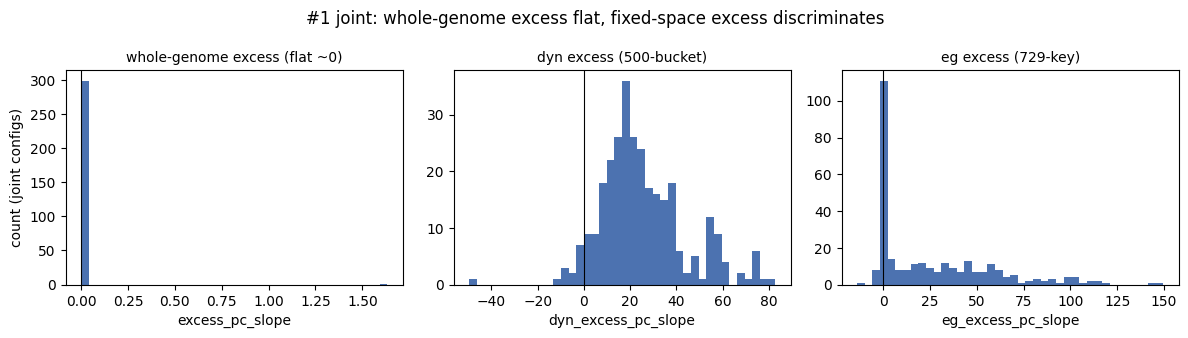

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in zip(
    axes,
    ["excess_pc_slope", "dyn_excess_pc_slope", "eg_excess_pc_slope"],
    ["whole-genome excess (flat ~0)", "dyn excess (500-bucket)", "eg excess (729-key)"],
):
    ax.hist(joint[col].dropna(), bins=40, color="#4C72B0")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(col)
axes[0].set_ylabel("count (joint configs)")
fig.suptitle("#1 joint: whole-genome excess flat, fixed-space excess discriminates", fontsize=12)
fig.tight_layout(); plt.show()


### The productive optimum: low `mu_lut`, high `m_scale` (composite), not in `dyn` alone

The composite ranking (the 2026-05-17 analysis's unweighted mean of five min-max normalized, positive-clipped keys; `eg` dropped for LUT-only), then `dyn_excess_pc_slope` binned over the two active levers. (R1 later shows the `mu_lut` optimum
is *conditional* on `m_scale` — see the `viability-brackets` draft.)

In [4]:
keys5 = ["excess_pc_slope", "eg_excess_pc_slope", "dyn_excess_pc_slope",
         "n_distinct_genomes_temporal_std", "unique_top_genomes"]
def composite_top(d, keys, k=5):
    c = d[(~d.extinct.astype(bool)) & (d.alive_density_mean <= 0.95)].copy()
    X = c[keys].clip(lower=0); c["composite"] = ((X - X.min()) / (X.max() - X.min())).mean(axis=1)
    return c.nlargest(k, "composite")
show = ["config_idx", "param_food_inc", "param_m_scale", "param_mu_lut", "param_tax_per_egene",
        "composite", "eg_excess_pc_slope", "dyn_excess_pc_slope"]
print("#1 joint, top-5 by composite:"); display(composite_top(joint, keys5)[show].round(3))
print("#2 LUT-only, top-5 by composite:")
display(composite_top(lut, [k for k in keys5 if k != "eg_excess_pc_slope"])[show].round(3))

#1 joint, top-5 by composite:


,config_idx,param_food_inc,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
28,41,0.018,2.5,0.01,0.001,0.519,142.743,36.759
198,210,0.010,1.2,0.03,0.001,0.499,91.918,57.387
7,13,0.010,1.2,0.03,0.001,0.476,91.364,58.666
70,70,0.018,1.5,0.01,0.001,0.467,113.079,25.741
26,43,0.013,1.5,0.06,0.001,0.460,80.654,55.520


#2 LUT-only, top-5 by composite:


,config_idx,param_food_inc,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
65,68,0.01,2.5,0.06,0.0,0.573,0.0,19.994
144,149,0.01,2.5,0.15,0.0,0.556,0.0,15.295
169,171,0.01,2.5,0.15,0.0,0.553,0.0,14.463
95,99,0.01,2.5,0.06,0.0,0.531,0.0,10.555
94,100,0.01,2.5,0.06,0.0,0.510,0.0,4.677


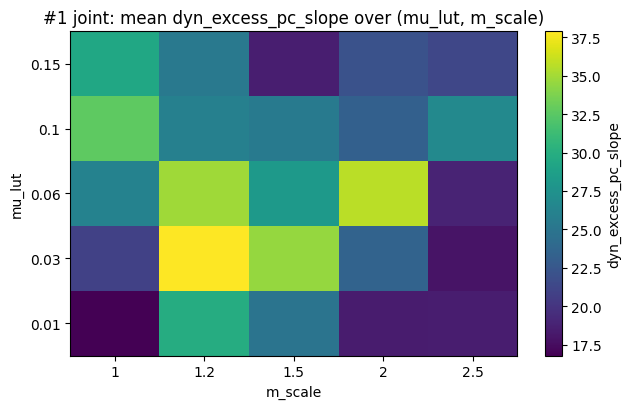

param_m_scale,1.0,1.2,1.5,2.0,2.5
param_mu_lut,,,,,
0.01,16.8,29.8,24.9,18.4,18.4
0.03,20.8,37.9,34.6,23.5,17.9
0.06,26.2,34.9,28.1,35.7,18.9
0.10,32.7,26.0,25.5,23.3,26.8
0.15,29.3,25.4,18.6,22.1,21.3


In [5]:
piv = (joint.groupby(["param_mu_lut", "param_m_scale"])
             .dyn_excess_pc_slope.mean().unstack())
fig, ax = plt.subplots(figsize=(6.5, 4.2))
im = ax.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{c:g}" for c in piv.columns])
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels([f"{r:g}" for r in piv.index])
ax.set_xlabel("m_scale"); ax.set_ylabel("mu_lut")
ax.set_title("#1 joint: mean dyn_excess_pc_slope over (mu_lut, m_scale)")
fig.colorbar(im, ax=ax, label="dyn_excess_pc_slope")
fig.tight_layout(); plt.show()
display(piv.round(1))

### Does egene-freeze reduce `dyn`-excess? Not in the marginal means

Comparing #1 (joint) vs #2 (LUT-only, egene frozen) at matched `mu_lut`. The 2026-05-17 analysis
read "freezing the egene lowers the *rule*-channel excess" from the top configs (~23-60 joint vs
~3-20 LUT-only). The marginal means below do not show it: the two curves cross, and LUT-only is
higher at `mu_lut` 0.01. The two-channel synergy is better tested on the causal controls
(`neutral-model-methodology`), which keep `tax_per_egene` fixed across arms. The `eg` excess
in the LUT-only scan is ≈ 0 by construction (egene frozen) — a built-in null.

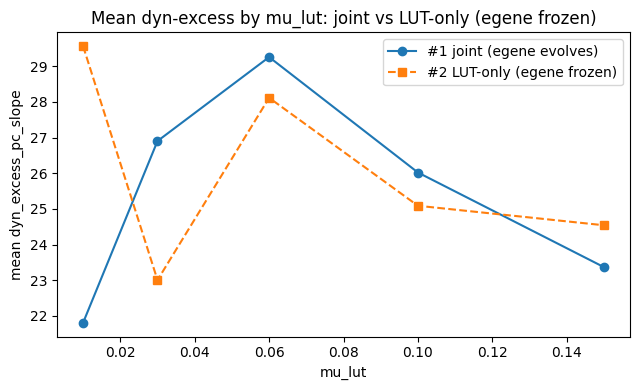

param_mu_lut   0.01  0.03   0.06   0.10   0.15
joint         21.81  26.9  29.25  26.02  23.37
LUT-only      29.56  23.0  28.11  25.09  24.54
all-row mean dyn_excess_pc_slope: joint 25.42, LUT-only 26.00
LUT-only eg_excess_pc_final mean (should be ~0, egene frozen): 0.0


In [6]:
def by_mulut(d):
    return d.groupby("param_mu_lut").dyn_excess_pc_slope.mean()
j = by_mulut(joint); l = by_mulut(lut)
common = sorted(set(j.index) & set(l.index))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(common, [j[k] for k in common], "o-", label="#1 joint (egene evolves)")
ax.plot(common, [l[k] for k in common], "s--", label="#2 LUT-only (egene frozen)")
ax.set_xlabel("mu_lut"); ax.set_ylabel("mean dyn_excess_pc_slope")
ax.set_title("Mean dyn-excess by mu_lut: joint vs LUT-only (egene frozen)")
ax.legend(); fig.tight_layout(); plt.show()
print(pd.DataFrame({"joint": j, "LUT-only": l}).round(2).T)
print("all-row mean dyn_excess_pc_slope: joint %.2f, LUT-only %.2f" % (joint.dyn_excess_pc_slope.mean(), lut.dyn_excess_pc_slope.mean()))
print("LUT-only eg_excess_pc_final mean (should be ~0, egene frozen):",
      round(lut.eg_excess_pc_final.mean(), 4))

*Sources:* `Research/Activity-metrics/Scans/2026-10-23_pure_evo_joint_standard/`, `Research/Activity-metrics/Scans/2026-10-23_pure_evo_lut_only_standard/` (standard-model rescans of `2026-05-17_pure_evo_joint/` and `2026-05-17_pure_evo_lut_only/`, which are the recorded legacy-rule results; recorded-vs-rescan comparison in the lab notebook's legacy section),
`Research/Activity-metrics/Scans/2026-05-17_pure_evo_analysis.md`, `Docs/devlog/2026-05-17_research-campaigns.md`.